# 例4-18 直方图反向投影

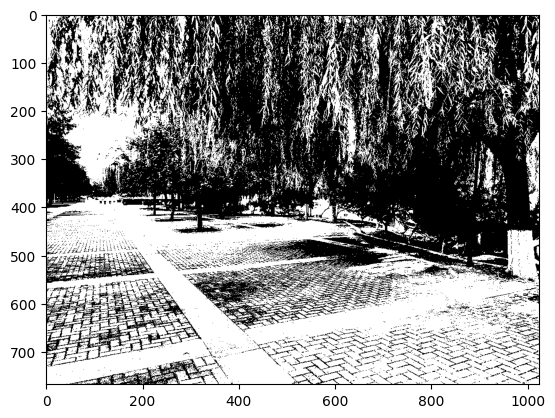

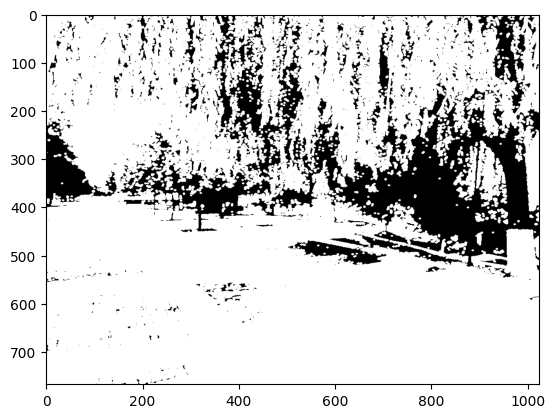

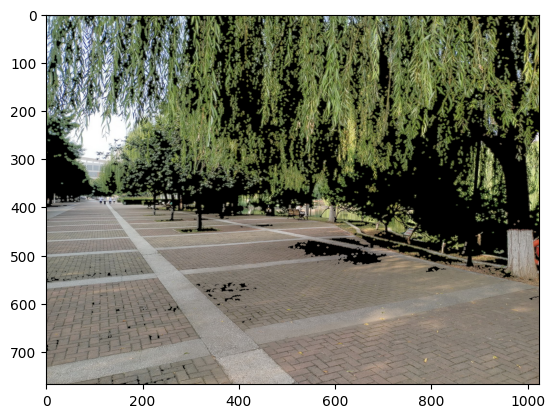

(768, 1024)


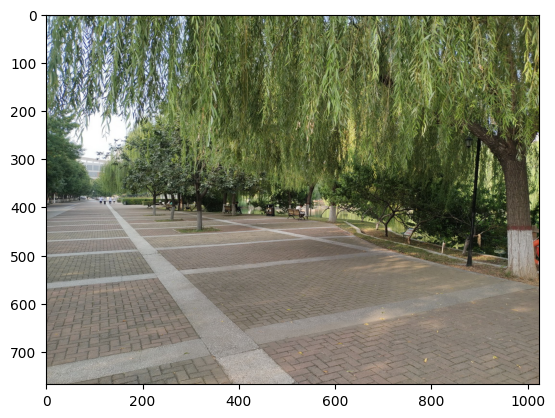

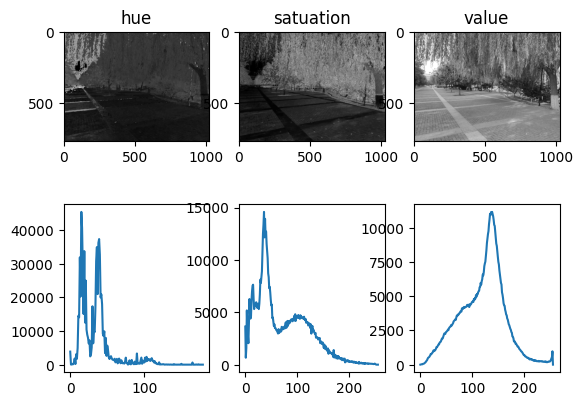

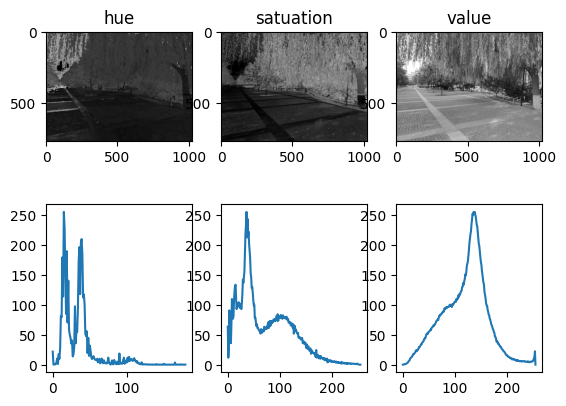

In [2]:
import numpy as np 
import matplotlib.pyplot as plt
import cv2 

path = '/home/aistudio/work/'
image_bgr = cv2.imread(path + 'campus_1024_768.jpg')
image_rgb = cv2.cvtColor(image_bgr,cv2.COLOR_BGR2RGB)
image_hsv = cv2.cvtColor(image_bgr,cv2.COLOR_BGR2HSV)
#im_h = image_hsv[:,:,0]
#im_s = image_hsv[:,:,1]
#im_v = image_hsv[:,:,2]
im_h,im_s,im_v = cv2.split(image_hsv)

hist_h =cv2.calcHist([im_h],[0],None,[180],[0,179])
hist_s = cv2.calcHist([im_s],[0],None,[256],[0,255])
hist_v = cv2.calcHist([im_v],[0],None,[256],[0,255])
hist_h_normed = hist_h.copy()
hist_s_normed = hist_s.copy()
hist_v_normed = hist_v.copy()

cv2.normalize(hist_h,hist_h_normed,0,255,cv2.NORM_MINMAX)
cv2.normalize(hist_s,hist_s_normed,0,255,cv2.NORM_MINMAX)
cv2.normalize(hist_v,hist_v_normed,0,255,cv2.NORM_MINMAX)
#print(hist_h_normed.sum())
#print(hist_h_normed)

#print(hist_h)
#print(hist_h_normed)

#print(image_hsv)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(5,5))
thres_value,im_v_binary = cv2.threshold(im_v,127,255,cv2.THRESH_BINARY)
im_v_blurred = im_v_binary.copy()
im_v_blurred = cv2.filter2D(im_v_binary,-1,kernel)
im_v_mask = cv2.merge((im_v_blurred,im_v_blurred,im_v_blurred))
im_rgb_segment = cv2.bitwise_and(image_rgb,im_v_mask)

plt.imshow(im_v_binary,'gray')
plt.show()

plt.imshow(im_v_blurred,'gray')
plt.show()

plt.imshow(im_rgb_segment)
plt.show()
print(im_v_binary.shape)


plt.imshow(image_rgb)
plt.show()

fig,axes = plt.subplots(2,3)
fig.figsize=(10,10)
axes[0][0].imshow(im_h,'gray')
axes[0][0].set_title('hue')
axes[1][0].plot(hist_h)
axes[0][1].imshow(im_s,'gray')
axes[0][1].set_title('satuation')
axes[1][1].plot(hist_s)
axes[0][2].imshow(im_v,'gray')
axes[0][2].set_title('value')
axes[1][2].plot(hist_v)
plt.show()


fig,axes = plt.subplots(2,3)
fig.figsize=(10,10)
axes[0][0].imshow(im_h,'gray')
axes[0][0].set_title('hue')
axes[1][0].plot(hist_h_normed)
axes[0][1].imshow(im_s,'gray')
axes[0][1].set_title('satuation')
axes[1][1].plot(hist_s_normed)
axes[0][2].imshow(im_v,'gray')
axes[0][2].set_title('value')
axes[1][2].plot(hist_v_normed)
plt.show()



## 二维直方图

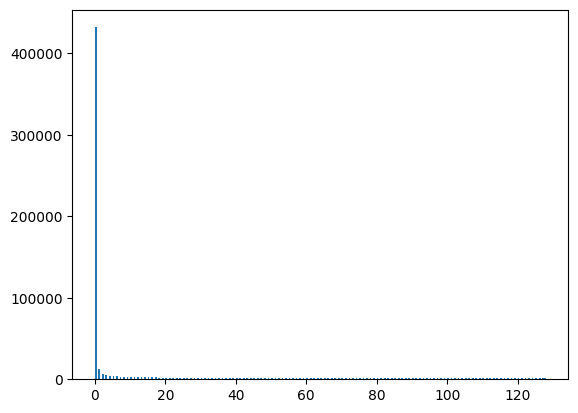

75.0


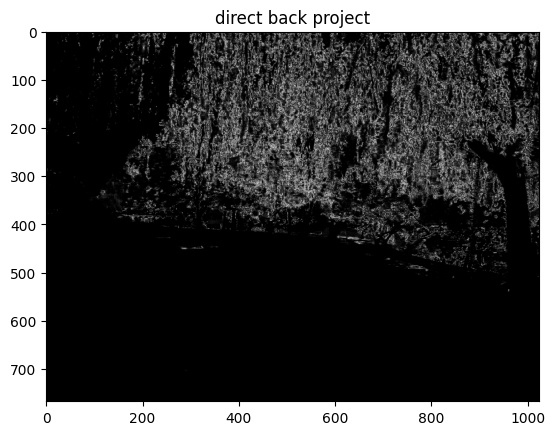

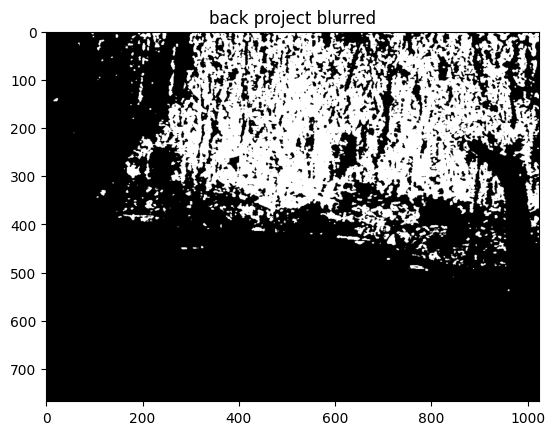

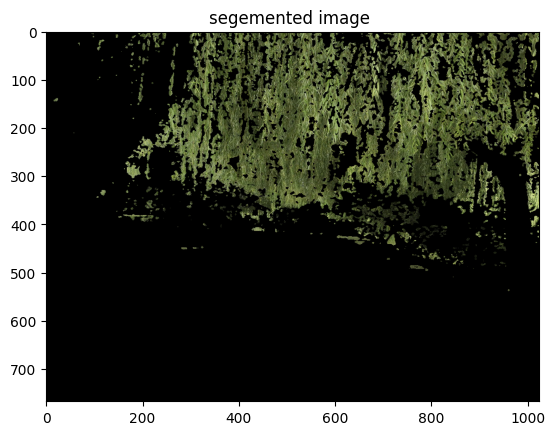

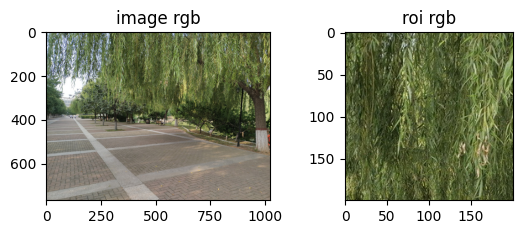

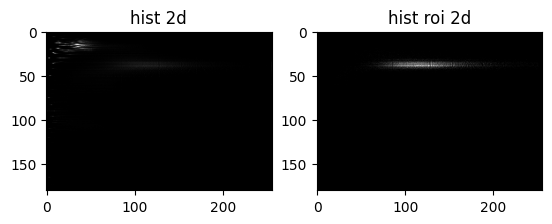

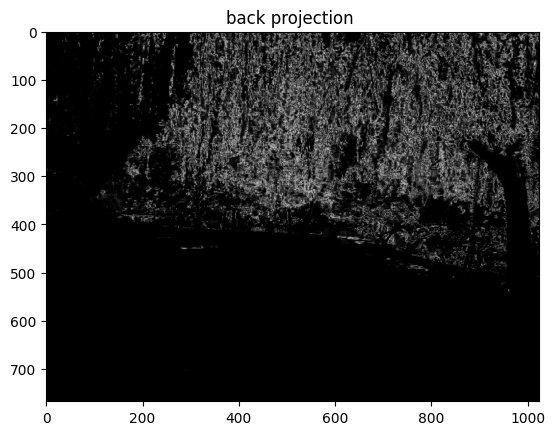

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import cv2 

path = '/home/aistudio/work/'
image_bgr = cv2.imread(path + 'campus_1024_768.jpg')
image_rgb = cv2.cvtColor(image_bgr,cv2.COLOR_BGR2RGB)
image_hsv = cv2.cvtColor(image_bgr,cv2.COLOR_BGR2HSV)

roi_bgr = cv2.imread(path + 'campus_200_200_willow.jpg')
#roi_bgr = cv2.imread(path + 'campus_200_200_floor.jpg')
roi_rgb = cv2.cvtColor(roi_bgr,cv2.COLOR_BGR2RGB)
roi_hsv = cv2.cvtColor(roi_bgr,cv2.COLOR_BGR2HSV)
roi_h,roi_s,roi_v = cv2.split(roi_hsv)

hist_hs = cv2.calcHist([image_hsv],[0,1],None,[180,256],[0,180,0,256])
hist_hs_normed = hist_hs.copy()
hist_hs_normed = cv2.normalize(hist_hs,0,255,cv2.NORM_MINMAX)

hist_hs_roi = cv2.calcHist([roi_hsv],[0,1],None,[180,256],[0,180,0,256])
hist_hs_roi_normed = hist_hs_roi.copy()
hist_hs_roi_normed = cv2.normalize(hist_hs_roi,0,255,cv2.NORM_MINMAX)


back_project = cv2.calcBackProject([image_hsv],[0,1],hist_hs_roi_normed,[0,180,0,256],1)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(5,5))
back_project_blurred = cv2.filter2D(back_project,-1,kernel)

plt.hist(back_project_blurred.ravel(),256,[0,128])
plt.show()

thres_value,back_project_binary = cv2.threshold(back_project_blurred,75,255,cv2.THRESH_BINARY)
print(thres_value)

mask = cv2.merge((back_project_binary,back_project_binary,back_project_binary))
image_segmented = cv2.bitwise_and(image_rgb,mask)

plt.imshow(back_project,'gray')
plt.title('direct back project')
plt.show()

plt.imshow(back_project_binary,'gray')
plt.title('back project blurred')
plt.show()

plt.imshow(image_segmented)
plt.title('segemented image ')
plt.show()

plt.subplot(2,2,1)
plt.imshow(image_rgb)
plt.title('image rgb')
plt.subplot(2,2,2)
plt.imshow(roi_rgb)
plt.title('roi rgb')
plt.show()
plt.subplot(2,2,3)
plt.imshow(hist_hs_normed,'gray')
plt.title('hist 2d')
plt.subplot(2,2,4)
plt.imshow(hist_hs_roi_normed,'gray')
plt.title('hist roi 2d')
plt.show()

plt.imshow(back_project,'gray')
plt.title('back projection ')
plt.show()

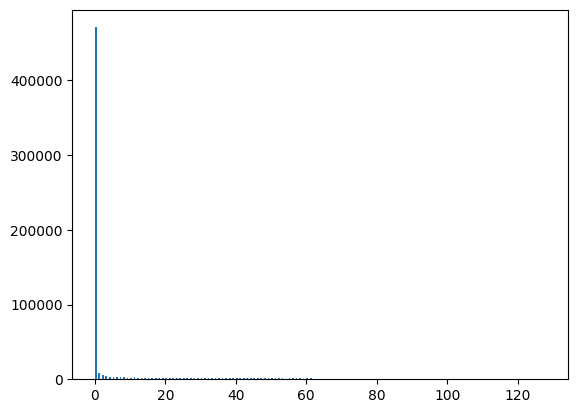

117.0


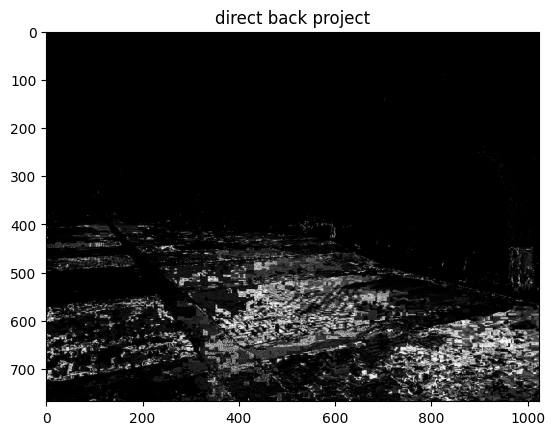

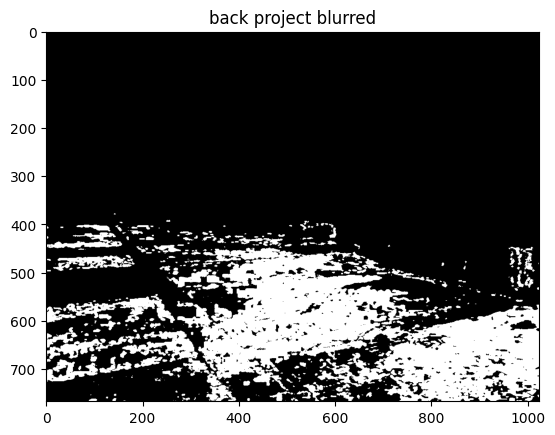

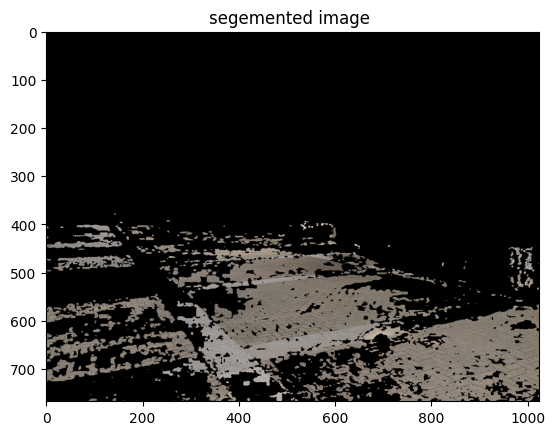

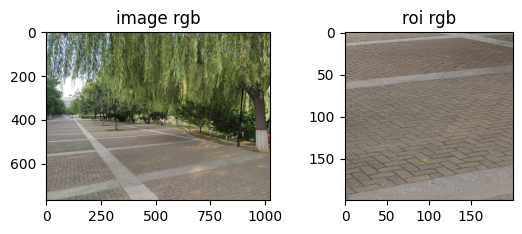

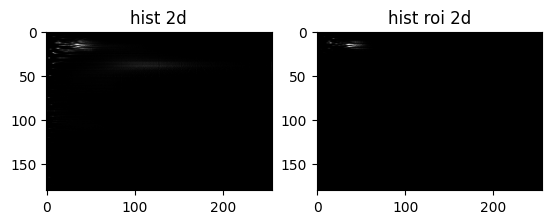

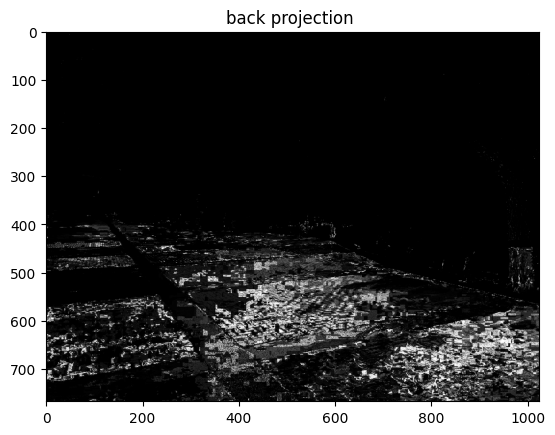

In [2]:
import numpy as np 
import matplotlib.pyplot as plt
import cv2 

path = '/home/aistudio/work/'
image_bgr = cv2.imread(path + 'campus_1024_768.jpg')
image_rgb = cv2.cvtColor(image_bgr,cv2.COLOR_BGR2RGB)
image_hsv = cv2.cvtColor(image_bgr,cv2.COLOR_BGR2HSV)

#roi_bgr = cv2.imread(path + 'campus_200_200_willow.jpg')
roi_bgr = cv2.imread(path + 'campus_200_200_floor.jpg')
roi_rgb = cv2.cvtColor(roi_bgr,cv2.COLOR_BGR2RGB)
roi_hsv = cv2.cvtColor(roi_bgr,cv2.COLOR_BGR2HSV)
roi_h,roi_s,roi_v = cv2.split(roi_hsv)





hist_hs = cv2.calcHist([image_hsv],[0,1],None,[180,256],[0,180,0,256])
hist_hs_normed = hist_hs.copy()
hist_hs_normed = cv2.normalize(hist_hs,0,255,cv2.NORM_MINMAX)





hist_hs_roi = cv2.calcHist([roi_hsv],[0,1],None,[180,256],[0,180,0,256])
hist_hs_roi_normed = hist_hs_roi.copy()
hist_hs_roi_normed = cv2.normalize(hist_hs_roi,0,255,cv2.NORM_MINMAX)


back_project = cv2.calcBackProject([image_hsv],[0,1],hist_hs_roi_normed,[0,180,0,256],1)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(5,5))
back_project_blurred = cv2.filter2D(back_project,-1,kernel)

plt.hist(back_project_blurred.ravel(),256,[0,128])
plt.show()

thres_value,back_project_binary = cv2.threshold(back_project_blurred,117,255,cv2.THRESH_BINARY)
print(thres_value)

mask = cv2.merge((back_project_binary,back_project_binary,back_project_binary))
image_segmented = cv2.bitwise_and(image_rgb,mask)




plt.imshow(back_project,'gray')
plt.title('direct back project')
plt.show()

plt.imshow(back_project_binary,'gray')
plt.title('back project blurred')
plt.show()

plt.imshow(image_segmented)
plt.title('segemented image ')
plt.show()



plt.subplot(2,2,1)
plt.imshow(image_rgb)
plt.title('image rgb')
plt.subplot(2,2,2)
plt.imshow(roi_rgb)
plt.title('roi rgb')
plt.show()
plt.subplot(2,2,3)
plt.imshow(hist_hs_normed,'gray')
plt.title('hist 2d')
plt.subplot(2,2,4)
plt.imshow(hist_hs_roi_normed,'gray')
plt.title('hist roi 2d')
plt.show()

plt.imshow(back_project,'gray')
plt.title('back projection ')
plt.show()

# histogram back projection implementation 
## gray implementation
+ indexing via color histograms 
    + Michael J. Swain


[[0.         0.03271348 0.16630029 ... 0.39837362 0.50596983 0.6692423 ]
 [0.         0.02180899 0.1553958  ... 0.33697012 0.46704827 0.55159524]
 [0.         0.01090449 0.14812984 ... 0.37319413 0.40541797 0.39054871]
 ...
 [0.71685473 0.77531349 0.88780824 ... 0.93575795 0.91143066 0.90163922]
 [0.80590889 0.80073315 0.89319619 ... 0.93828147 0.91310664 0.91120748]
 [0.90241741 0.84536634 0.86295997 ... 0.94470185 0.90836223 0.90341374]]
[[0.         0.         0.         ... 1.         0.63697314 0.38419574]
 [0.         0.         0.         ... 0.         1.         0.85948855]
 [0.         0.         0.         ... 0.         0.         1.        ]
 ...
 [1.         0.51506585 0.33283094 ... 1.         0.87644529 0.93375325]
 [1.         0.66821921 1.         ... 0.93375325 0.87644529 0.87644529]
 [0.66821921 1.         1.         ... 0.93375325 0.87644529 0.87644529]]


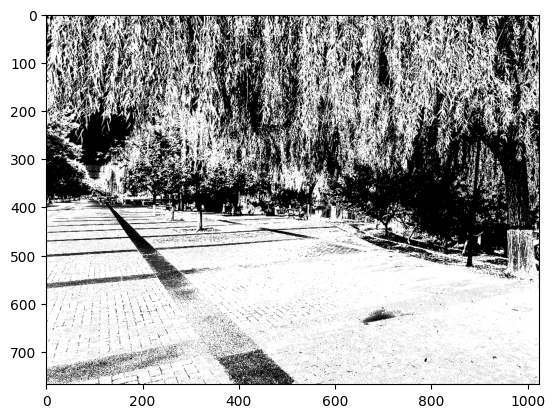

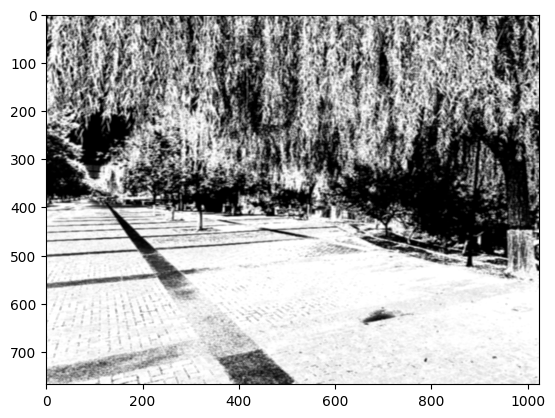

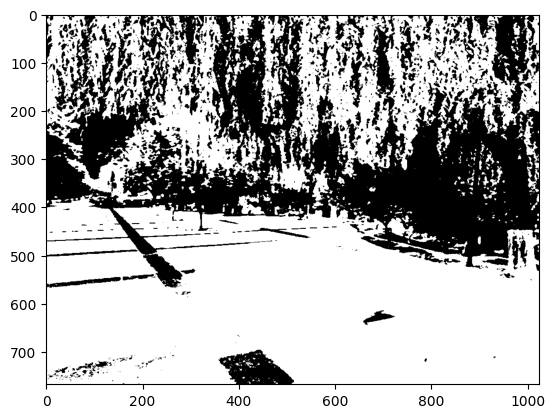

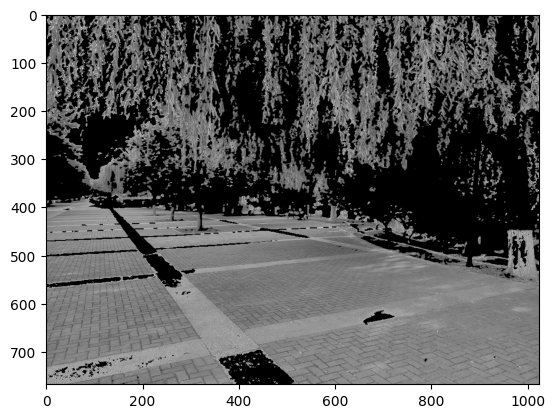

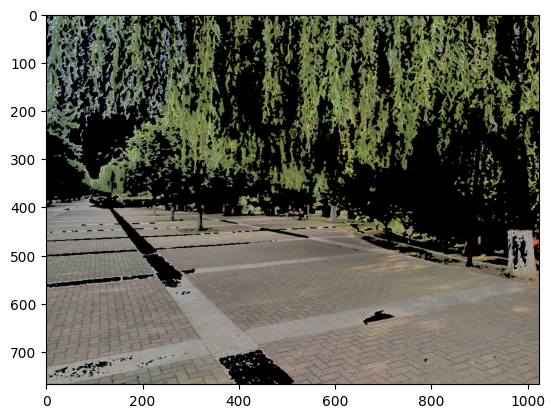

[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.00624946 0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.00492752 0.00486292 0.         0.00467002
 0.00929589 0.00462172 0.         0.02262463 0.03112997 0.00448569
 0.03165262 0.03999711 0.05757837 0.09877543 0.08566798 0.07210011
 0.09594889 0.19782192 0.25000107 0.22436807 0.35794529 0.3654424
 0.35910136 0.42851549 0.55931586 0.71118897 0.81833023 0.77948534
 0.76784211 0.973

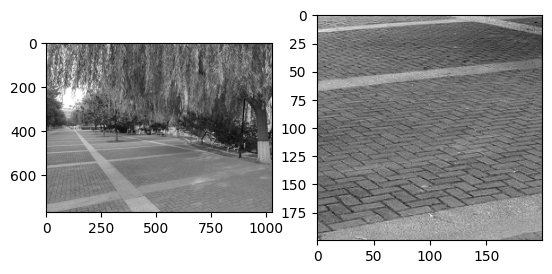

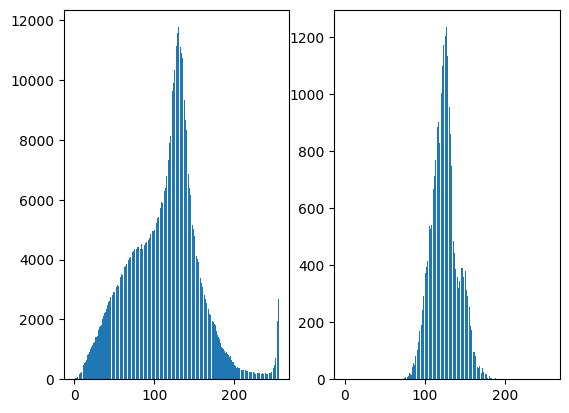

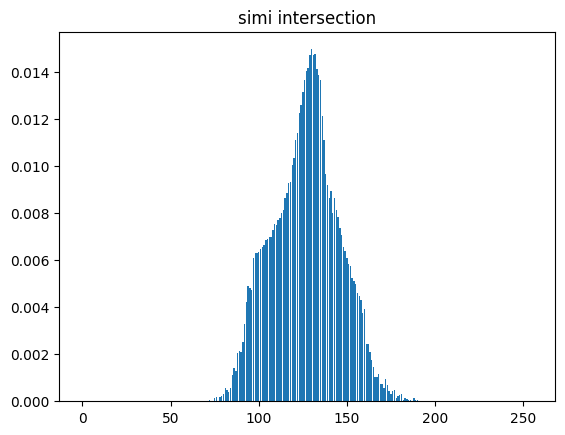

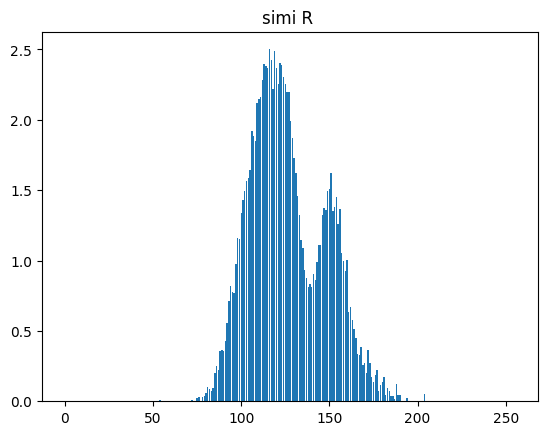

In [51]:
import numpy as np 
import matplotlib.pyplot as plt
import cv2 

path = '/home/aistudio/work/'
image_bgr = cv2.imread(path + 'campus_1024_768.jpg')
image_rgb = cv2.cvtColor(image_bgr,cv2.COLOR_BGR2RGB)
image_hsv = cv2.cvtColor(image_bgr,cv2.COLOR_BGR2HSV)
image_gray = cv2.cvtColor(image_bgr,cv2.COLOR_BGR2GRAY)
#roi_bgr = cv2.imread(path + 'campus_200_200_willow.jpg')
roi_bgr = cv2.imread(path + 'campus_200_200_floor.jpg')
roi_rgb = cv2.cvtColor(roi_bgr,cv2.COLOR_BGR2RGB)
roi_hsv = cv2.cvtColor(roi_bgr,cv2.COLOR_BGR2HSV)
roi_h,roi_s,roi_v = cv2.split(roi_hsv)
roi_gray = cv2.cvtColor(roi_bgr,cv2.COLOR_BGR2GRAY)

im_hist  = cv2.calcHist([image_gray],[0],None,[256],[0,256])
roi_hist = cv2.calcHist([roi_gray],[0],None,[256],[0,256])

im_hist_norm = im_hist.ravel()/np.sum(im_hist)
roi_hist_norm = roi_hist.ravel()/np.sum(roi_hist)

simi_intersection = np.minimum(im_hist_norm,roi_hist_norm)
simi_R = np.zeros((256,),dtype = np.float64)
for i in range(0,256):
    if im_hist_norm[i]>10**-10:
        simi_R[i]  = roi_hist_norm[i]/im_hist_norm[i]

im_back_prj  = np.zeros(image_gray.shape,dtype =np.float64)
im_back_prj = np.minimum(cv2.LUT(image_gray,simi_R),1)
r = int(5)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(r,r))
im_back_prj_blurred = cv2.filter2D(im_back_prj,-1,kernel/np.sum(kernel.ravel()))
thres = 0.8
im_back_prj_thres = np.zeros(image_gray.shape,dtype =np.uint8)
im_back_prj_thres[im_back_prj_blurred<0.5] = 0
im_back_prj_thres[im_back_prj_blurred>=0.5] = 255
im_back_prj_seg = np.bitwise_and(image_gray,im_back_prj_thres)
im_back_prj_seg_color = np.bitwise_and(image_rgb,np.dstack((im_back_prj_thres,im_back_prj_thres,im_back_prj_thres)))
print(back_prj_blurred)


print(im_back_prj)
plt.imshow(im_back_prj,'gray')
plt.show()

plt.imshow(im_back_prj_blurred,'gray')
plt.show()
plt.imshow(im_back_prj_thres,'gray')
plt.show()

plt.imshow(im_back_prj_seg,'gray')
plt.show()

plt.imshow(im_back_prj_seg_color,'gray')
plt.show()

print(simi_R)

plt.subplot(1,2,1)
plt.imshow(image_gray,'gray')
plt.subplot(1,2,2)
plt.imshow(roi_gray,'gray')
plt.show()

plt.subplot(1,2,1)
plt.bar(np.arange(0,256),im_hist.ravel())
plt.subplot(1,2,2)
plt.bar(np.arange(0,256),roi_hist.ravel())
plt.show()
plt.bar(np.arange(0,256),simi_intersection)
plt.title('simi intersection')
plt.show()

plt.bar(np.arange(0,256),simi_R)
plt.title('simi R ')
plt.show()









# histogram back projection implementation 
## color implementation
+ indexing via color histograms 
    + Michael J. Swain

(180, 256)


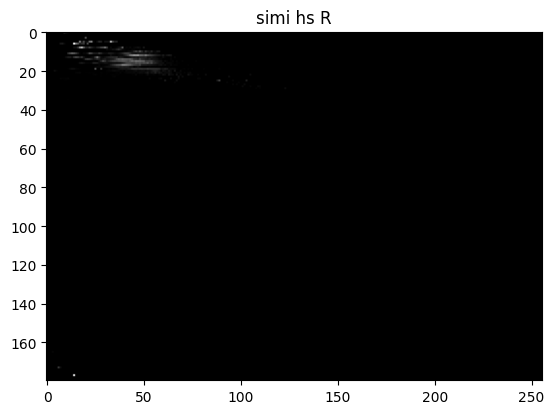

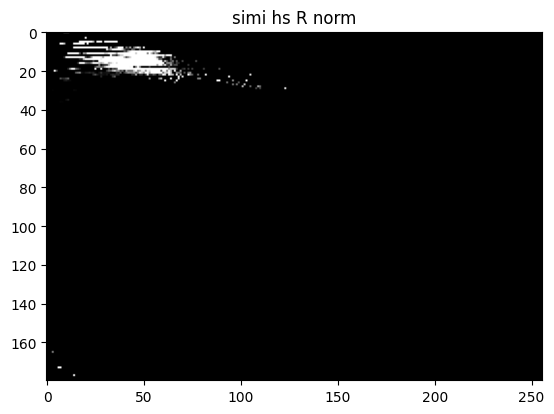

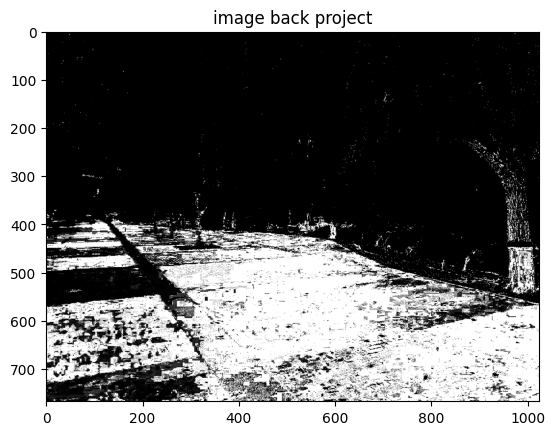

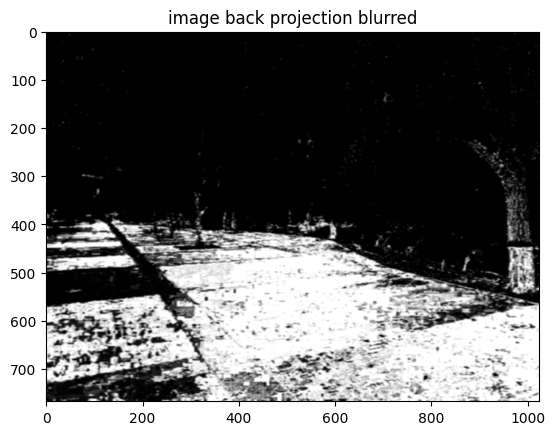

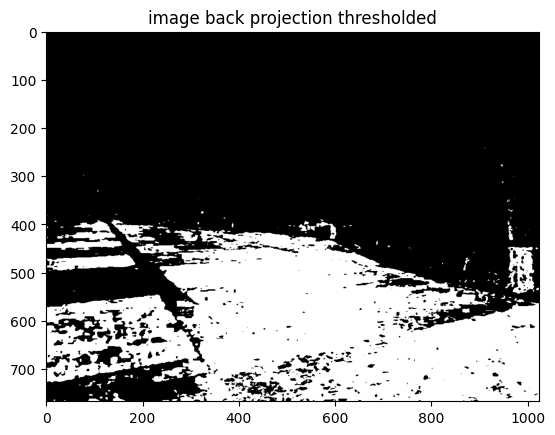

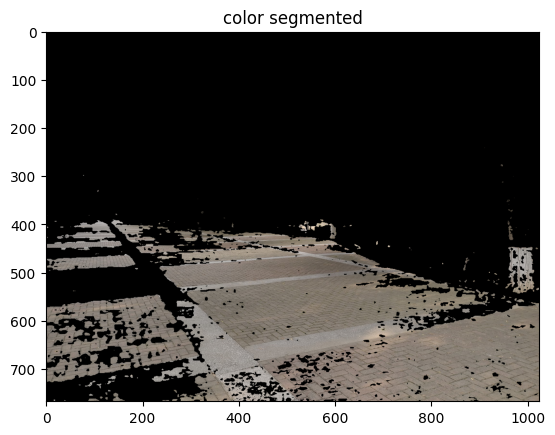

In [82]:
import numpy as np 
import matplotlib.pyplot as plt
import cv2 

path = '/home/aistudio/work/'
image_bgr = cv2.imread(path + 'campus_1024_768.jpg')
image_rgb = cv2.cvtColor(image_bgr,cv2.COLOR_BGR2RGB)
image_hsv = cv2.cvtColor(image_bgr,cv2.COLOR_BGR2HSV)
image_gray = cv2.cvtColor(image_bgr,cv2.COLOR_BGR2GRAY)
#roi_bgr = cv2.imread(path + 'campus_200_200_willow.jpg')
roi_bgr = cv2.imread(path + 'campus_200_200_floor.jpg')
roi_rgb = cv2.cvtColor(roi_bgr,cv2.COLOR_BGR2RGB)
roi_hsv = cv2.cvtColor(roi_bgr,cv2.COLOR_BGR2HSV)
roi_h,roi_s,roi_v = cv2.split(roi_hsv)
roi_gray = cv2.cvtColor(roi_bgr,cv2.COLOR_BGR2GRAY)

im_hs_hist  = cv2.calcHist([image_hsv],[0,1],None,[180,256],[0,180,0,256])
roi_hs_hist = cv2.calcHist([roi_hsv],[0,1],None,[180,256],[0,180,0,256])
print(im_hs_hist.shape)
im_hs_hist_norm = im_hs_hist/np.sum(im_hist.ravel())
roi_hs_hist_norm = roi_hs_hist/np.sum(roi_hist.ravel())
simi_hs_R = np.zeros((180,256),dtype = np.float64)
for i in range(0,180):
    for j in range(0,256):
        if im_hs_hist_norm[i,j]>10**-20:
            simi_hs_R[i,j]  = roi_hs_hist_norm[i,j]/im_hs_hist_norm[i,j]

simi_hs_R_norm = np.minimum(simi_hs_R,1.0)


rows,cols,chs = image_rgb.shape
im_color_back_prj = np.zeros((rows,cols),dtype = np.float64) 
for i in range(0,rows):
    for j in range(0,cols):
        color = image_rgb[i,j,:]
        hsv = cv2.cvtColor(np.array([[color]]),cv2.COLOR_RGB2HSV)
        h = hsv[0,0,0]
        s = hsv[0,0,1]
        im_color_back_prj[i,j] = simi_hs_R_norm[h,s]
r = int(5)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(r,r))
im_color_back_prj_blurred = cv2.filter2D(im_color_back_prj,-1,kernel/np.sum(kernel.ravel()))
thres = 0.8
im_color_back_prj_thres = np.zeros((rows,cols),dtype =np.uint8)
im_color_back_prj_thres[im_color_back_prj_blurred<0.5] = 0
im_color_back_prj_thres[im_color_back_prj_blurred>=0.5] = 255
im_color_back_prj_seg = np.bitwise_and(image_rgb,\
np.dstack((im_color_back_prj_thres,im_color_back_prj_thres,im_color_back_prj_thres)))

plt.imshow(simi_hs_R,'gray')
plt.title('simi hs R')
plt.show()

plt.imshow(simi_hs_R_norm,'gray')
plt.title('simi hs R norm')
plt.show()

plt.imshow(im_color_back_prj,'gray')
plt.title('image back project')
plt.show()

plt.imshow(im_color_back_prj_blurred,'gray')
plt.title('image back projection blurred')
plt.show()
plt.imshow(im_color_back_prj_thres,'gray')
plt.title('image back projection thresholded')
plt.show()

plt.imshow(im_color_back_prj_seg,'gray')
plt.title('color segmented')
plt.show()


In [83]:
 color = image_rgb[1,1,:]
 print(color)
 newColor = color.reshape(1,1,3)
 print(newColor)

[227 249 255]
[[[227 249 255]]]


In [84]:
new = np.array([[color]])
print(new.shape)


(1, 1, 3)


In [74]:
hsv = cv2.cvtColor(np.array([[color]]),cv2.COLOR_RGB2HSV)
print(hsv.shape)

(1, 1, 3)
